# EN3160 – Assignment 3: Neural Networks

**Name:** Anthony C.S.B.  
**Index No:** 230045X  
**GitHub:** https://github.com/BashithaAnthony/EN3160-Assignment-3-on-Neural-Networks


## Question 1 – Dense network with manual back-propagation

Listing 1 is a single-layer network trained with MSE loss, with the forward pass and gradients written by hand and I kept that style (no `autograd`, no `nn.Linear`) and made the three requested changes:

- **(a)** add a middle layer with 100 nodes and a sigmoid activation,
- **(b)** replace the MSE loss with cross-entropy,
- **(c)** train for 10 epochs and report the training and test accuracies.

I first run it with exactly the hyperparameters of Listing 1, and then with modified hyperparameters, and compare the two.


### Setup and data loading
The data pipeline is the same as in Listing 1 (CIFAR-10, normalised to $[-1, 1]$, batch size 50). Images are flattened to $3072$ inputs.


In [3]:
import numpy as np
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

torch.manual_seed(0)

In [4]:
# 1. Data loading (same as Listing 1; num_workers=0 so it runs on Windows)
transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

batch_size = 50

trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                        download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=True, num_workers=0)

testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                       download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size,
                                         shuffle=False, num_workers=0)

Din = 3 * 32 * 32   # flattened CIFAR-10 image
H = 100             # middle layer nodes
K = 10              # classes
epochs = 10

### (a), (b) Network and gradients

For a batch of $N$ flattened images $X$ with one-hot labels $Y$:

$$Z_1 = XW_1 + b_1,\quad H = \sigma(Z_1),\quad S = HW_2 + b_2,\quad P = \mathrm{softmax}(S)$$

$$L = -\frac{1}{N}\sum_{n}\sum_{k} Y_{nk}\log P_{nk} \;+\; \lambda\left(\lVert W_1\rVert^2 + \lVert W_2\rVert^2\right)$$

Back-propagating by hand:

$$\frac{\partial L}{\partial S} = \frac{P - Y}{N},\qquad \frac{\partial L}{\partial W_2} = H^\top\frac{\partial L}{\partial S} + 2\lambda W_2,\qquad \frac{\partial L}{\partial b_2} = \sum_n \frac{\partial L}{\partial S}$$

$$\frac{\partial L}{\partial Z_1} = \left(\frac{\partial L}{\partial S}W_2^\top\right)\odot H\odot(1-H),\qquad \frac{\partial L}{\partial W_1} = X^\top\frac{\partial L}{\partial Z_1} + 2\lambda W_1,\qquad \frac{\partial L}{\partial b_1} = \sum_n \frac{\partial L}{\partial Z_1}$$

In the code the softmax subtracts the row maximum before exponentiating to avoid overflow. $\lambda$ (`reg`) is 0, as in Listing 1.


### Implementation
The forward pass, loss, backward pass and accuracy function are kept as separate functions so that the training loop stays short.


In [5]:
def init_params(std):
    w1 = torch.randn(Din, H) * std
    b1 = torch.zeros(H)
    w2 = torch.randn(H, K) * std
    b2 = torch.zeros(K)
    return [w1, b1, w2, b2]


def forward(x, params):
    w1, b1, w2, b2 = params
    h1 = torch.sigmoid(x.mm(w1) + b1)      # middle layer (sigmoid)
    scores = h1.mm(w2) + b2                # output layer (logits)
    return h1, scores


def softmax(scores):
    shifted = scores - scores.max(dim=1, keepdim=True).values   # numerical stability
    exp_scores = torch.exp(shifted)
    return exp_scores / exp_scores.sum(dim=1, keepdim=True)


def loss_fn(probs, y_onehot, params, reg):
    ce = -torch.sum(y_onehot * torch.log(probs + 1e-8)) / probs.shape[0]
    w1, _, w2, _ = params
    return ce + reg * (torch.sum(w1 ** 2) + torch.sum(w2 ** 2))


def backward(x, y_onehot, h1, probs, params, reg):
    w1, _, w2, _ = params
    N = x.shape[0]
    dscores = (probs - y_onehot) / N                  # softmax + cross-entropy
    dw2 = h1.t().mm(dscores) + 2 * reg * w2
    db2 = dscores.sum(dim=0)
    dz1 = dscores.mm(w2.t()) * h1 * (1.0 - h1)        # through the sigmoid
    dw1 = x.t().mm(dz1) + 2 * reg * w1
    db1 = dz1.sum(dim=0)
    return dw1, db1, dw2, db2


def accuracy(loader, params):
    correct, total = 0, 0
    with torch.no_grad():
        for inputs, labels in loader:
            x = inputs.view(inputs.shape[0], -1)
            _, scores = forward(x, params)
            correct += (scores.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)
    return 100 * correct / total

In [6]:
def run_experiment(std, lr, lr_decay=0.9, reg=0.0, epochs=10, seed=0):
    torch.manual_seed(seed)          # same init and batch order for every run
    lr0 = lr
    params = init_params(std)
    loss_history, epoch_loss = [], []

    for t in range(epochs):
        running_loss = 0.0
        for inputs, labels in trainloader:
            x = inputs.view(inputs.shape[0], -1)
            y = nn.functional.one_hot(labels, K).float()

            h1, scores = forward(x, params)
            probs = softmax(scores)
            loss = loss_fn(probs, y, params, reg)
            loss_history.append(loss.item())
            running_loss += loss.item()

            grads = backward(x, y, h1, probs, params, reg)
            for p, g in zip(params, grads):
                p -= lr * g                      # SGD update (in place)

        epoch_loss.append(running_loss / len(trainloader))
        print(f"Epoch {t + 1}/{epochs} | avg loss: {epoch_loss[-1]:.4f} | lr: {lr:.2e}")
        lr *= lr_decay

    return {"loss_history": loss_history, "epoch_loss": epoch_loss,
            "train_acc": accuracy(trainloader, params),
            "test_acc": accuracy(testloader, params),
            "std": std, "lr": lr0}

`run_experiment` trains the network with plain SGD and learning-rate decay (0.9 per epoch, as in Listing 1) and returns the loss history and final accuracies. The seed is fixed inside it, so both runs start from the same random numbers and see the same batch order.


### Gradient check
To make sure the hand-derived gradients are right, I compared them with PyTorch autograd on one batch (in float64, with a non-zero `reg`). Autograd is used only for this check, not for training.


In [7]:
# Compare the hand-written gradients with autograd on one batch (float64)
torch.manual_seed(0)
xb, yb = next(iter(trainloader))
x = xb.view(xb.shape[0], -1).double()
y = nn.functional.one_hot(yb, K).double()
reg_test = 1e-3                      # non-zero so the regularization gradient is tested too

params_auto = [p.double().requires_grad_() for p in init_params(1e-2)]
_, scores = forward(x, params_auto)
loss_fn(softmax(scores), y, params_auto, reg_test).backward()

with torch.no_grad():
    params_man = [p.detach() for p in params_auto]
    h1, scores = forward(x, params_man)
    grads_man = backward(x, y, h1, softmax(scores), params_man, reg_test)

for name, p, g in zip(["w1", "b1", "w2", "b2"], params_auto, grads_man):
    rel_err = ((p.grad - g).abs().max() / (p.grad.abs().max() + 1e-12)).item()
    print(f"{name}: max relative error = {rel_err:.2e}")

w1: max relative error = 9.74e-08
b1: max relative error = 1.02e-07
w2: max relative error = 1.02e-07
b2: max relative error = 1.02e-07


All relative errors are tiny (around $10^{-7}$ or smaller, the small residual comes from the `1e-8` added inside the log), so the back-propagation is correct.


In [8]:
def plot_run(res, title, window=100):
    hist = np.array(res["loss_history"])
    smooth = np.convolve(hist, np.ones(window) / window, mode="valid")

    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(hist, alpha=0.3, label="per iteration")
    ax[0].plot(np.arange(window - 1, len(hist)), smooth, label=f"moving average ({window})")
    ax[0].set_title(f"{title}: loss history")
    ax[0].set_xlabel("Iteration")
    ax[0].set_ylabel("Loss")
    ax[0].legend()

    ax[1].plot(range(1, len(res["epoch_loss"]) + 1), res["epoch_loss"], marker="o")
    ax[1].set_title(f"{title}: average loss per epoch")
    ax[1].set_xlabel("Epoch")
    ax[1].set_ylabel("Loss")
    plt.tight_layout()
    plt.show()

### (c) Run 1 – settings exactly as in Listing 1
Only changes (a) and (b) are applied. Hyperparameters are unchanged: `std = 1e-5`, `lr = 2e-6`, `lr_decay = 0.9`, `reg = 0`, batch size 50, 10 epochs.


Epoch 1/10 | avg loss: 2.3026 | lr: 2.00e-06
Epoch 2/10 | avg loss: 2.3026 | lr: 1.80e-06
Epoch 3/10 | avg loss: 2.3026 | lr: 1.62e-06
Epoch 4/10 | avg loss: 2.3026 | lr: 1.46e-06
Epoch 5/10 | avg loss: 2.3026 | lr: 1.31e-06
Epoch 6/10 | avg loss: 2.3026 | lr: 1.18e-06
Epoch 7/10 | avg loss: 2.3026 | lr: 1.06e-06
Epoch 8/10 | avg loss: 2.3026 | lr: 9.57e-07
Epoch 9/10 | avg loss: 2.3026 | lr: 8.61e-07
Epoch 10/10 | avg loss: 2.3026 | lr: 7.75e-07

Training accuracy: 10.00%
Test accuracy:     10.00%


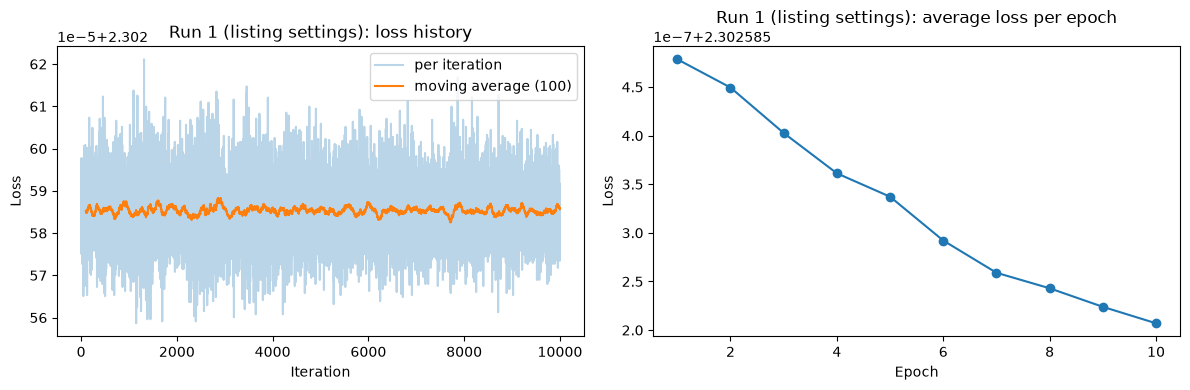

In [9]:
res1 = run_experiment(std=1e-5, lr=2e-6, lr_decay=0.9, reg=0.0, epochs=10)
print(f"\nTraining accuracy: {res1['train_acc']:.2f}%")
print(f"Test accuracy:     {res1['test_acc']:.2f}%")
plot_run(res1, "Run 1 (listing settings)")

**Observation.** The loss stays close to $\ln 10 \approx 2.30$, which is the loss of a network that guesses uniformly over the 10 classes, and the accuracies stay near chance level (10%). The network is effectively not learning. Two reasons:

- With weights of order $10^{-5}$, $Z_1 \approx 0$ for every image, so every hidden node outputs about $\sigma(0) = 0.5$. The hidden layer passes almost no information about the input.
- The gradient reaching $W_1$ is multiplied by $W_2$, which is also about $10^{-5}$, and with `lr = 2e-6` the weights hardly move in 10 epochs.

These values were suitable for the original single-layer MSE network, but not for this deeper network with cross-entropy.


### Run 2 – modified hyperparameters
I changed only the following two (everything else is the same as in Run 1):

- `std`: $10^{-5} \rightarrow 10^{-2}$, so the pre-activations $Z_1$ have a useful spread and the sigmoid outputs differ between images.
- `lr`: $2\times10^{-6} \rightarrow 0.1$. The cross-entropy gradient $(P-Y)/N$ is bounded and averaged over the batch, so a much larger step can be used.


Epoch 1/10 | avg loss: 1.9000 | lr: 1.00e-01
Epoch 2/10 | avg loss: 1.7177 | lr: 9.00e-02
Epoch 3/10 | avg loss: 1.6512 | lr: 8.10e-02
Epoch 4/10 | avg loss: 1.6038 | lr: 7.29e-02
Epoch 5/10 | avg loss: 1.5647 | lr: 6.56e-02
Epoch 6/10 | avg loss: 1.5299 | lr: 5.90e-02
Epoch 7/10 | avg loss: 1.5001 | lr: 5.31e-02
Epoch 8/10 | avg loss: 1.4729 | lr: 4.78e-02
Epoch 9/10 | avg loss: 1.4487 | lr: 4.30e-02
Epoch 10/10 | avg loss: 1.4273 | lr: 3.87e-02

Training accuracy: 51.80%
Test accuracy:     47.53%


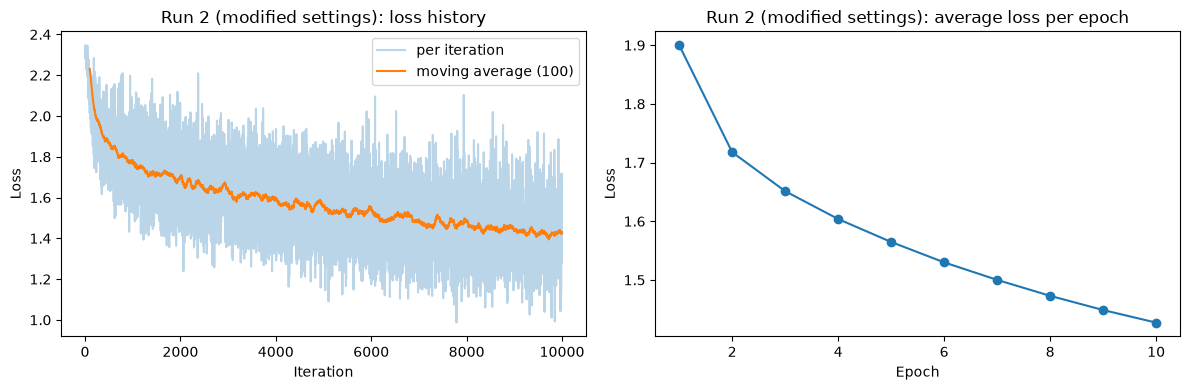

In [10]:
res2 = run_experiment(std=1e-2, lr=0.1, lr_decay=0.9, reg=0.0, epochs=10)
print(f"\nTraining accuracy: {res2['train_acc']:.2f}%")
print(f"Test accuracy:     {res2['test_acc']:.2f}%")
plot_run(res2, "Run 2 (modified settings)")

**Observation.** Now the loss decreases steadily over the 10 epochs and both accuracies are far above chance. The per-iteration loss is noisy because each step uses only 50 images, so the moving average is used to see the trend.


### Results and discussion


| Run | std | initial lr | Final avg loss | Train acc (%) | Test acc (%) |
|---|---|---|---|---|---|
| Run 1 (listing settings) | 1e-05 | 2e-06 | 2.3026 | 10.00 | 10.00 |
| Run 2 (modified settings) | 0.01 | 0.1 | 1.4273 | 51.80 | 47.53 |


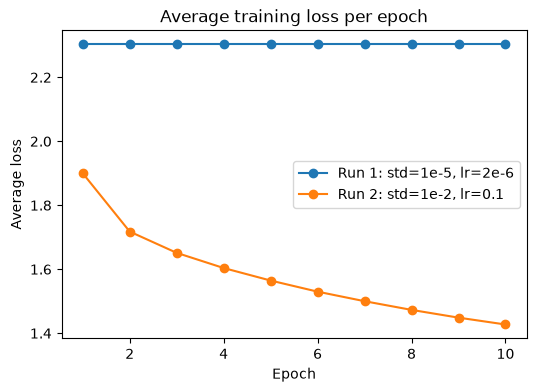

In [12]:
from IPython.display import Markdown, display

rows = ""
for name, r in [("Run 1 (listing settings)", res1), ("Run 2 (modified settings)", res2)]:
    rows += (f"| {name} | {r['std']:g} | {r['lr']:g} | {r['epoch_loss'][-1]:.4f} "
             f"| {r['train_acc']:.2f} | {r['test_acc']:.2f} |\n")

display(Markdown("| Run | std | initial lr | Final avg loss | Train acc (%) | Test acc (%) |\n"
                 "|---|---|---|---|---|---|\n" + rows))

plt.figure(figsize=(6, 4))
plt.plot(range(1, 11), res1["epoch_loss"], marker="o", label="Run 1: std=1e-5, lr=2e-6")
plt.plot(range(1, 11), res2["epoch_loss"], marker="o", label="Run 2: std=1e-2, lr=0.1")
plt.xlabel("Epoch")
plt.ylabel("Average loss")
plt.title("Average training loss per epoch")
plt.legend()
plt.show()

- **Note:** the training and test accuracies for the Listing 1 settings (Run 1) and for the modified settings (Run 2) are given in the table above. Run 2 is the working model.
- The hyperparameters of Listing 1 do not work for the two-layer network with cross-entropy (small initial weights and a tiny learning rate), so the network has to be re-tuned after the architecture and loss are changed. Changing `std` and `lr` was what made the difference, not the architecture alone.
- In Run 2 the training accuracy is higher than the test accuracy, so the network fits the training set a bit better than unseen data (mild over-fitting).
